<a href="https://colab.research.google.com/github/2DObjectDetector/T25/blob/main/Emma_Sloan_Ass2_T25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Set-Up

In [ ]:
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')
!rm -rf /content/kitti3k_yolo
!cp -r /content/drive/MyDrive/kitti3k_yolo /content/kitti3k_yolo
dataset_yaml = "/content/kitti3k_yolo/kitti3k.yaml"

# install YOLO
!pip install -U ultralytics
from ultralytics import YOLO

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 90.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.9/63.9 kB 8.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
!pip install -q grad-cam
from pytorch_grad_cam import EigenCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 56.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# get the best configuration from t2.2

model = YOLO("yolo11n.pt")
model.train(
    data=dataset_yaml, epochs=40, imgsz=640, batch=16, lr0=0.001, freeze=10,
    workers=2, cache="ram", device=0, exist_ok=True, pretrained=True,
)

In [ ]:
# inspect the model's architecture to choose layers

print(model.model)

DetectionModel(
  (model): Sequential(
    (0): Conv(
      (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (1): Conv(
      (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (2): C3k2(
      (cv1): Conv(
        (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(48, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
   

In [ ]:
for i, layer in enumerate(model.model.model):
    print(i, type(layer).__name__)

0 Conv
1 Conv
2 C3k2
3 Conv
4 C3k2
5 Conv
6 C3k2
7 Conv
8 C3k2
9 SPPF
10 C2PSA
11 Upsample
12 Concat
13 C3k2
14 Upsample
15 Concat
16 C3k2
17 Conv
18 Concat
19 C3k2
20 Conv
21 Concat
22 C3k2
23 Detect


In [ ]:
image_ids = ['000136', '000232', '000189']

image_paths = [f'/content/kitti3k_yolo/images/val/{img_id}.png' for img_id in image_ids]

class_names = {0: 'Cyclist', 1: 'Pedestrian', 2: 'Car'}

# pick one specific image
chosen_img_id = '000189'

# First chosen layer

In [ ]:
import cv2
import numpy as np
import torch

img_path = image_paths[image_ids.index(chosen_img_id)]
img = cv2.imread(img_path)
img = cv2.resize(img, (640, 640))
img_float = np.float32(img) / 255

img_tensor = torch.from_numpy(img_float).permute(2, 0, 1).unsqueeze(0).float()

target_layers = [model.model.model[4]]

cam = EigenCAM(model.model, target_layers)
grayscale_cam = cam(img_tensor, targets=[])[0]

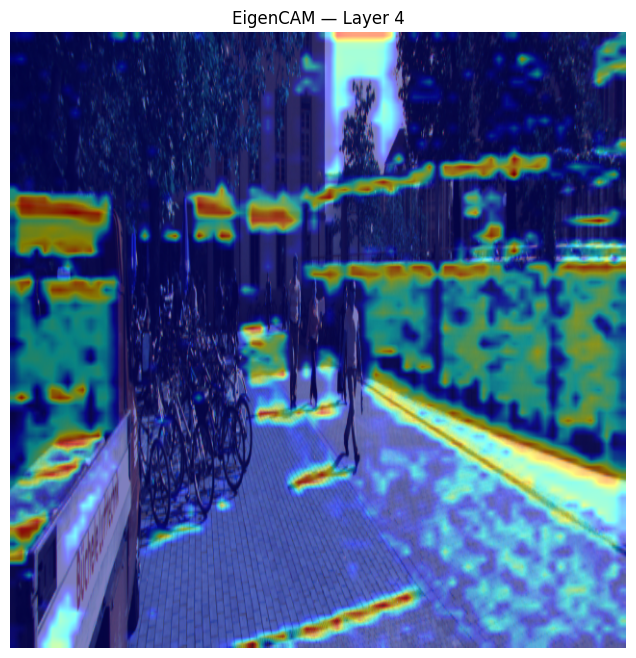

In [ ]:
# plot the heat map

cam_image = show_cam_on_image(img_float, grayscale_cam, use_rgb=True)

plt.figure(figsize=(10, 8))
plt.imshow(cam_image)
plt.title(f'EigenCAM — Layer {4}')
plt.axis('off')
plt.show()

# Second chosen layer

In [ ]:
import cv2
import numpy as np
import torch

img_path = image_paths[image_ids.index(chosen_img_id)]
img = cv2.imread(img_path)
img = cv2.resize(img, (640, 640))
img_float = np.float32(img) / 255

img_tensor = torch.from_numpy(img_float).permute(2, 0, 1).unsqueeze(0).float()

target_layers = [model.model.model[21]]

cam = EigenCAM(model.model, target_layers)
grayscale_cam = cam(img_tensor, targets=[])[0]

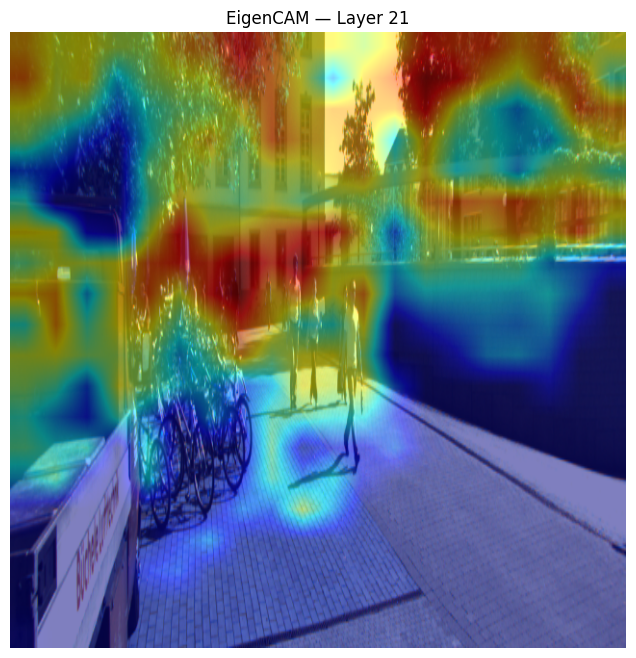

In [ ]:
# plot the heat map

cam_image = show_cam_on_image(img_float, grayscale_cam, use_rgb=True)

plt.figure(figsize=(10, 8))
plt.imshow(cam_image)
plt.title(f'EigenCAM — Layer {21}')
plt.axis('off')
plt.show()